# VQE Carbon Capture Study: Ten Amines + CO2

 Figures:
   - **Figure A** — logarithmic |VQE/HF − CASCI| energy-error plot with a
     1 kcal/mol chemical-accuracy band.
   - **Figure 3** — VQE convergence profiles (energy vs. COBYLA iteration) for
     NH3·CO2, MEA·CO2, and Piperazine·CO2, each against its CASCI reference
     with a ±1 kcal/mol chemical-accuracy band.
   - **Figure 4** — multi-method energy comparison (HF/CASCI/VQE) relative
     to HF, across all ten amines, species vs. complexes.
   - **Figure C** — quantum resource scaling (qubits, UCCSD parameters).



## 0. Setup

In [ ]:
try:
    import qiskit, qiskit_nature, qiskit_algorithms, pyscf  # noqa: F401
    print("Core dependencies already present.")
except ImportError:
    import subprocess, sys
    pkgs = ["qiskit>=2.0,<3.0", "qiskit-nature>=0.7.2",
            "qiskit-algorithms>=0.3.0", "qiskit-aer>=0.15",
            "pyscf>=2.4.0", "matplotlib", "numpy"]
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])
    except subprocess.CalledProcessError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                                "--break-system-packages", *pkgs])
    print("Dependencies installed.")


Dependencies installed.


## 1. Molecular Geometries

DFT-optimized (B3LYP/def2-SVP, ORCA/WebMO/Avogadro2) Cartesian coordinates for every amine, the shared CO2 monomer, and every amine-CO2 pre-reactive complex.

In [ ]:
%%writefile configs.py
"""
Molecular coordinates (DFT-optimized, B3LYP/def2-SVP via ORCA/WebMO/Avogadro2,
Angstroms) for the ten-amine + CO2 ADAPT-VQE carbon-capture study.

Geometries are pooled verbatim from the per-molecule notebooks
(NH3, methylamine, ethylamine, propylamine, butylamine, MEA, DEA,
TEA, ethylenediamine, piperazine). Each amine is paired with CO2 in a
single pre-reactive donor-acceptor complex (N...C separation ~2-3 A),
representing the lone-pair-to-carbon nucleophilic attack geometry.
"""

# ── Shared CO2 geometry (identical across all complexes) ──
CO2_COORDS = """
  C          -3.41445366834561      2.74493578700907      0.04842193002017
  O          -4.60237457458717      2.74427018151385      0.04501207715020
  O          -2.22653275706722      2.74559903147708      0.05183099282963
"""

# ── Per-amine geometries: amine + amine-CO2 complex ──

# Ammonia (NH3)
NH3_COORDS = """
  N          -3.36581734597081      1.53058806020204     -0.04600295665861
  H          -4.11992290885604      1.37141635147074      0.64108773678707
  H          -3.50853413487407      2.50488104860899     -0.35662811072278
  H          -2.50718961029908      1.57099053971823      0.52603633059432
"""

NH3_CO2_COMPLEX_COORDS = """
  N          -3.33420460463515      1.73515662491694      0.12861389604088
  H          -4.09472996516369      1.37939491211052      0.72890562091588
  H          -3.57523131024303      2.72665325347715     -0.02656010252606
  H          -2.51055833728701      1.76786370124896      0.74979283730911
  C          -2.83352912329359      0.27696887347799     -2.16948262169434
  O          -1.67995556531178      0.56027659715697     -2.13295620180024
  O          -3.97134709406570     -0.04953496238855     -2.27320742824524
"""

# Methylamine
methylamine_COORDS = """
  N          -2.66085473112020      2.24996031918673      0.07191853366948
  C          -1.18135759318083      2.34130836644824     -0.02613556306603
  H          -3.05300883657070      3.07091855879530     -0.41812269024992
  H          -2.95809370131449      1.44281700272027     -0.50085072149688
  H          -0.84106768476867      3.21941153652360      0.52024000524988
  H          -0.73795603541088      1.46049110578576      0.43535165444146
  H          -0.81213741763422      2.41254511054009     -1.05255021854798
"""

methylamine_CO2_COMPLEX_COORDS = """
  N          -2.51415204829387      2.27296028756167     -0.03685696800020
  C          -1.04816911360178      2.37192675865246     -0.26045318559817
  H          -2.94880689120436      3.10126468404065     -0.47562240457027
  H          -2.85716630428357      1.47434888716042     -0.59559800908846
  H          -0.66238096954636      3.23590589630399      0.27837659933018
  H          -0.56582805595638      1.47911312617052      0.13419380269373
  H          -0.77232588795417      2.47306769010839     -1.31287622305006
  C          -3.20465531495675      1.96238136057118      2.63052546561087
  O          -3.18920498329709      0.77844269290175      2.52857127389293
  O          -3.24036743090563      3.13659661652894      2.80973664877944
"""

# Ethylamine
ethylamine_COORDS = """
  C          -5.62086046883852      3.13199111090915     -0.11487511782665
  C          -4.21757010149296      3.74660021675399      0.04791583631835
  H          -6.31260706379012      3.86218404644757     -0.52484536728900
  H          -5.58240699910619      2.28100233335970     -0.78735012187417
  H          -6.00219986906970      2.80098435587890      0.84646772156529
  N          -3.66994220372946      4.15095573650438     -1.27640093850906
  H          -4.26730288147320      4.58489219184563      0.75132499113221
  H          -3.54209305783802      3.00379974870016      0.47493865758173
  H          -4.26476310998981      4.91681015894284     -1.63396494509707
  H          -2.75281824467201      4.59601610065767     -1.10665571600163
"""

ethylamine_CO2_COMPLEX_COORDS = """
  C          -5.73170489225508      3.28200649736294      0.18100599651640
  C          -4.28765604742989      3.81840334258819      0.20512845187979
  H          -6.41162050493667      4.03053529656196     -0.21560554597519
  H          -5.79622747393466      2.39540316830069     -0.44154269627846
  H          -6.05330056862005      3.02472248670848      1.18567114334813
  N          -3.82660594826540      4.14690955236296     -1.17311413199670
  H          -4.23323125902488      4.68327290261460      0.87456185972011
  H          -3.62056514702334      3.05318379071048      0.60495093007008
  H          -4.41204749053343      4.92596710542552     -1.51715537272570
  H          -2.88058910233310      4.55417326589767     -1.08908007861988
  C          -3.77973152022553      2.16908299776556     -3.11675284805817
  O          -3.14629884484849      1.43083251745159     -2.43427935416909
  O          -4.41086220056939      2.85252307624930     -3.85632035371130
"""

# Propylamine
Propylamine_COORDS = """
  C          -3.37554584655212      0.63127029938807      0.00151526989387
  C          -2.17517174682282      1.59463791863113     -0.06786844650593
  H          -4.30865809304475      1.17901908862017     -0.08973063612080
  H          -3.32979715726145     -0.09848834422922     -0.80140005006619
  H          -3.38664635956609      0.09610238817401      0.94657005875541
  C          -0.82426967453138      0.85715093590445      0.06404296412853
  H          -2.18833158195521      2.13345231769481     -1.01276190868726
  H          -2.25681792764863      2.33350056056681      0.72758063805549
  N           0.30587091117876      1.81837645298582     -0.06167923134918
  H          -0.80109963675570      0.30783069752392      1.01143059006314
  H          -0.72999516775821      0.12436594367782     -0.73862039699023
  H           0.26330384305895      2.45139780732384      0.75419647465779
  H           1.18008543765866      1.28410393373837      0.07369767416535
"""

Propylamine_CO2_COMPLEX_COORDS = """
  C          -3.39725791973222      0.62085525920706     -0.05116158596312
  C          -2.19404699853533      1.57495354223247      0.07328038889320
  H          -4.32342956749560      1.18414766737814     -0.11367603724768
  H          -3.31099277812295      0.00751469436634     -0.94319163468646
  H          -3.45737629580260     -0.03818532117785      0.81002073698811
  C          -0.85371342371841      0.81302251532078      0.17151009893714
  H          -2.16083466243876      2.23849503108259     -0.78801678972521
  H          -2.31502615350346      2.19871680071892      0.95735444531080
  N           0.28712073308913      1.76806311978163      0.24952931233443
  H          -0.88441316885168      0.13570220702112      1.03127726885341
  H          -0.71496662925711      0.20074499249304     -0.72078570272571
  H           0.18865441710194      2.29446548769126      1.13338489661215
  H           1.14591829883676      1.20782720618733      0.37785136409086
  C           0.64555250564814      3.54826314017883     -1.85393819127103
  O           1.04325578646675      2.69233094461170     -2.57595158009893
  O           0.25943785631544      4.45623871290661     -1.19148599030195
"""

# Butylamine
Butylamine_COORDS = """
  C          -5.22234720508109      1.39636690116652     -0.01538977009508
  C          -3.86230886629215      2.11904635389855     -0.06815755164647
  H          -6.03718621749314      2.11081339673083     -0.08627241391056
  H          -5.31550766338089      0.69153908691586     -0.83631400643224
  H          -5.33018327640530      0.84836477030274      0.91592989054607
  C          -2.67213245901897      1.13950887559949      0.03040686454601
  H          -3.78985453880107      2.68193934226229     -0.99716569264593
  H          -3.80473828701549      2.83726372803431      0.74770068526265
  C          -1.31019064050350      1.86588819246728     -0.02831004578061
  H          -2.73086707558642      0.58047112069566      0.96164369798961
  H          -2.72768623377617      0.41906816538892     -0.78389217145479
  N          -0.19517994206654      0.89081661566801      0.12459004504064
  H          -1.24110296909905      2.43463397411707     -0.96187526766498
  H          -1.24287795457222      2.58066579088388      0.79307297846186
  H          -0.20950879614684      0.27492435410693     -0.70527772848736
  H           0.68880412523885      1.41894633176165      0.03651648627118
"""

Butylamine_CO2_COMPLEX_COORDS = """
  C          -5.24229300546285      1.39090394641550      0.00783614615225
  C          -3.91156722117069      2.15204467678922     -0.14814138425850
  H          -6.08375147083525      2.07185067900487     -0.07992355460129
  H          -5.34102708476911      0.62755570612277     -0.75829854292216
  H          -5.29570760541819      0.90657790264753      0.97832693730669
  C          -2.68565134422171      1.22055381693645     -0.02755811399680
  H          -3.89281661831504      2.64999457485659     -1.11612910417402
  H          -3.84934184982456      2.92725242324339      0.61337621090522
  C          -1.35375812755308      1.98589248327250     -0.18909842793587
  H          -2.68860235220531      0.72839230964720      0.94251555438567
  H          -2.74508627682426      0.44368137422354     -0.78794968953929
  N          -0.19824947877056      1.06296562585567     -0.00517615704908
  H          -1.33267325019861      2.48376038562216     -1.16414694197188
  H          -1.28440425375167      2.76200619656135      0.57442846918214
  H          -0.22363453412533      0.38032763053849     -0.78061372625203
  H           0.66280904677456      1.60859747114171     -0.17512330435517
  C           0.13803618957968     -0.22910392881891      2.43116450450349
  O          -0.98055978884937     -0.02111061465136      2.77438672209822
  O           1.26828302594143     -0.47468465940870      2.15841440252241
"""

# Monoethanolamine (MEA)
MEA_COORDS = """
  C          -2.45855403709612      2.71783678023922      0.02080724169708
  C          -1.11091622069416      1.90608770588042     -0.04465200711155
  H          -2.51129074934948      3.38834611262546     -0.86026981286349
  H          -3.54712587783815      1.30593458343302      0.81978003810108
  O          -3.65548047524673      1.86925800149223     -0.03521021070082
  N           0.06382563943968      2.87388449427033     -0.07186169601799
  H          -2.44274974341415      3.36093637633061      0.93299778699851
  H          -1.07551778229621      1.18759516629267      0.80603021248031
  H          -1.08580118902240      1.31761502211746     -0.98092407735031
  H           0.08921664201840      3.29304974200653      0.90483719180811
  H           0.92349079349931      2.24901301531204     -0.06288166704094
"""

MEA_CO2_COMPLEX_COORDS = """
  C          -2.12514805962636      2.89751944855769      0.15478194424406
  C          -1.12651435310401      1.71947766849358     -0.01390054464502
  H          -1.73856203134174      3.76814997217361     -0.38109891994655
  H          -3.74587731193716      1.84784789727242      0.14711086372097
  O          -3.41891641071718      2.61261311630265     -0.39268856893563
  N           0.20634484806372      2.09308411872591      0.53358457064922
  H          -2.18983933224564      3.16411626097080      1.21754071445282
  H          -1.53814060489099      0.82389144595057      0.46464679242873
  H          -1.00933498702611      1.50047921176107     -1.07568678434770
  H           0.10592293657476      2.19322163235207      1.55734120029668
  H           0.82438425067684      1.27397244812780      0.41455287470393
  C           1.51656451422308      4.41811926088535     -0.30057440728550
  O           1.93916340098806      4.58050911384883      0.79844546872082
  O           1.12954014036276      4.31952440457758     -1.41944520405684
"""

# Diethanolamine (DEA)
DEA_COORDS = """
  N          -1.03853289503453      1.53575513972905     -0.02362522480226
  C          -2.26141974016679      2.38043076988701      0.01416400066668
  H          -3.51991348707375      0.84462074794777      0.89805357262751
  C           0.19490967427694      2.36502597803057      0.00892806335975
  H          -4.74642978996671      2.73144420138481     -0.80817569494378
  C          -3.52539973542766      1.47798804502297      0.00636111095564
  H          -1.04091012521906      0.96076173385940      0.83582919377514
  C           1.44883655602160      1.44890893861275     -0.01325592575777
  H           0.20352481145031      3.00443606300881     -0.87433219233492
  H           0.23303242829245      3.01855955629088      0.88833228173128
  O           2.67704109360238      2.18665968858207     -0.06223345135340
  H          -2.29182044016485      3.03900599302830      0.88865562491808
  H          -2.26186108766423      3.01488524843176     -0.87376469541587
  O          -4.74512360582008      2.23023931749959      0.04688311584458
  H          -3.48234443450117      0.81770188429591     -0.86764116278879
  H           1.41989095666792      0.77827202429671      0.85488686027531
  H           1.41449444869518      0.82668802344080     -0.91106211242413
  H           2.68328837203206      2.70060364665083      0.78555963566696
"""

DEA_CO2_COMPLEX_COORDS = """
  N          -1.06605277752774      1.59092117104051      0.02466069570950
  C          -2.26283210080855      2.47521686080647      0.08699607463721
  H          -3.53921835372924      1.00691456941375      1.05621153066684
  C           0.18905201954804      2.39025901371581      0.08142909678612
  H          -4.77159989369046      2.89161053697398     -0.64650142998693
  C          -3.55858592705555      1.62124102634801      0.15130599434311
  H          -1.08377881520765      1.00319918050314      0.87574046023077
  C           1.42436869978938      1.45010608474001      0.13880768859669
  H           0.24672233160418      3.00503929755251     -0.81771614352332
  H           0.20509199100370      3.06774685482080      0.94260117613548
  O           2.66530292280250      2.16538379209492      0.08125688833252
  H          -2.23444525810976      3.15250756305159      0.94664870544398
  H          -2.27608796522307      3.08903345277002     -0.81528315351308
  O          -4.74369797320397      2.42407764975383      0.22684825833088
  H          -3.57981039795794      0.94511056512905     -0.71072150943363
  H           1.36148227409069      0.82998729627386      1.04183000719429
  H           1.39960243760269      0.77912836101157     -0.72345686090335
  H           2.66235343546759      2.72020869768686      0.90294191787895
  C          -1.11583135552722      0.18857255565013     -2.51475875496040
  O          -0.13594302441851     -0.42781478772260     -2.24879857583244
  O          -2.09752326944904      0.77900325838565     -2.83145506613320
"""

# Triethanolamine (TEA)
TEA_COORDS = """
  N          -0.46491101441668      1.75948978603099      0.05404173692547
  C          -1.76742619111557      2.47314707660986     -0.06059092809000
  H           2.25524692141855      1.16202427123085     -0.30374770146087
  C           0.66361501944558      2.65979561677114     -0.31361245608353
  C          -2.90350887260296      1.72762591146978      0.69625940790954
  H          -1.65501241764097      3.45659715325691      0.39470206671616
  H          -2.06210482009564      2.62660681792760     -1.10517323809261
  H           2.91081254166326      3.80703382407823      0.42574930163755
  O          -4.11637847580101      2.49252186739313      0.73714572344831
  H           1.94433844785515      1.90329360584908      1.26887567906362
  C           2.02550296478118      2.10643626010340      0.19466872948611
  H           0.72433066076505      2.83559091738099     -1.39277052588522
  H           0.48851565637664      3.62378874607092      0.16468149158709
  H          -2.59142493088110      1.57197391259916      1.73200208389484
  H          -4.38936445329892      2.56113759466160     -0.21348606625825
  O           3.11521079491925      2.99130829992010     -0.09872730726741
  H          -3.07203792312756      0.74215194724732      0.24797366099162
  C          -0.44962083433847      0.48726585808382     -0.73519368043994
  C          -0.28384452305607     -0.74996259756980      0.19507666919619
  H          -1.37243105369981      0.37513473618356     -1.30494698752801
  H           0.36629801278509      0.50003569232305     -1.45915478993835
  O          -0.32368864443989     -1.98886594981989     -0.52643437392200
  H           0.64344923245165     -0.64675404459738      0.77016766522180
  H          -1.10984725496334     -0.77496394898279      0.90980100887120
  H           0.47685815701660     -1.95365935422164     -1.11003416998328
"""

TEA_CO2_COMPLEX_COORDS = """
  N          -0.49345788780626      1.78158344502825     -0.04658397116299
  C          -1.80717894526435      2.46728314471730     -0.22762393841397
  H           2.23913859778272      1.23537171871126     -0.49324732243748
  C           0.61057148846086      2.69463105098135     -0.46760896536098
  C          -2.97473298606573      1.70723195961056      0.46532704666284
  H          -1.73479401818383      3.45392965417723      0.22983598594726
  H          -2.04584464274943      2.61581961935598     -1.28682416226857
  H           2.86725218316705      3.89971219766569      0.18147372872970
  O          -4.18370126590096      2.47952091793423      0.47070620376001
  H           1.97344221140882      2.00389991574911      1.07659789357782
  C           2.00437516651275      2.18308087560617     -0.00363393784627
  H           0.62629554872242      2.85111745712843     -1.55110539610813
  H           0.43238361478263      3.66367289015585     -0.00046130530033
  H          -2.70973105881730      1.52371941886798      1.50926343761741
  H          -4.42011082548042      2.56360877227743     -0.48845000477275
  O           3.05548703327062      3.09126573776803     -0.35981974445814
  H          -3.12927715193853      0.73405859453114     -0.01307633634430
  C          -0.44542570582920      0.47842841283637     -0.78843831760301
  C          -0.26267858404259     -0.71720953460942      0.19103514608821
  H          -1.36008022215268      0.32473124466866     -1.36065697157836
  H           0.37515792295232      0.48005015590900     -1.50655898464126
  O          -0.28541273973410     -1.98470340005013     -0.47930743022327
  H           0.66444184833619     -0.57845639935169      0.75930080241379
  H          -1.08773272155772     -0.72388520577353      0.90763991696309
  H           0.51377781126021     -1.96189212206894     -1.06544767000242
  C          -0.27621428236560      1.95380879776819      3.19351545114756
  O          -1.15776099818803      1.17492318773441      3.35661598083955
  O           0.60747560942018      2.73540449267094      3.05193486477500
"""

# Ethylenediamine (en)
en_COORDS = """
  N          -3.88084779752610      1.72052615391183      0.07398531205392
  C          -2.79044393344100      2.72555363692602     -0.05429261199023
  H          -4.77670362551016      2.23276265053292      0.02202556075272
  H          -3.86699284067314      1.14121660384221     -0.78179919342503
  C          -1.41368170686901      2.02547142862668      0.00042765294097
  H          -2.85448219773199      3.31058773036091     -0.97691328315113
  H          -2.87469769027998      3.42129056340828      0.78195372820106
  N          -0.32328730862356      3.03047112049172     -0.12807470149245
  H          -1.34958920529099      1.44057217208947      0.92313120626731
  H          -1.32946291796510      1.32960056537882     -0.83571079783100
  H          -0.33695797107511      3.60983148158903      0.72767617516850
  H           0.57257319498615      2.51822989284208     -0.07627304749463
"""

en_CO2_COMPLEX_COORDS = """
  N          -3.85420273541287      1.82529941183414     -0.09897897861509
  C          -2.74150904331229      2.81346473359813     -0.17125134512360
  H          -4.73819487144483      2.35228013162275     -0.19150717414504
  H          -3.81092188184636      1.25087355271342     -0.95699612957041
  C          -1.37858065901395      2.09042012019620     -0.08005797133806
  H          -2.76710353695483      3.41300541549870     -1.08602504355005
  H          -2.84487225235018      3.49681905172556      0.67302687937018
  N          -0.27134640447462      3.08303799607141     -0.14495213352622
  H          -1.35992177197118      1.48554666916060      0.83154125001980
  H          -1.27275124294419      1.41306931089084     -0.92888495174139
  H          -0.30518120082000      3.63691533141659      0.72700906239204
  H           0.61476094340761      2.55576149103623     -0.07817951203472
  C          -4.11366486729951      0.25824452102723      2.18310987578996
  O          -5.21733992127890     -0.04165523966481      1.86153148108988
  O          -3.01898055428386      0.51384450287300      2.56949269098270
"""

# Piperazine
Piperazine_COORDS = """
  C          -2.97827292087702      2.19231376732892      0.16287583502168
  C          -2.91299704955231      0.66794284721640     -0.12982542478326
  H          -0.48735186335294      2.46251790241621      1.23924536896420
  H           0.31182431374995      2.79797225385166     -0.29604493395783
  N          -1.78939608952887      2.93624845945968     -0.33857524165664
  N          -1.66459975045483      0.02849003694107      0.37110787893029
  H          -3.76583859727469      0.16668037774921      0.32822158160428
  H          -2.96639307114520      0.50236354474380     -1.20687169117743
  C          -0.54094888522625      2.29680175837870      0.16223071527184
  C          -0.47570196006219      0.77239718779817     -0.13033942090516
  H          -3.87106958374798      2.61875600537885     -0.29480276993706
  H          -3.04517966439714      2.35271926988550      1.23995088391801
  H          -1.78532022647444      2.83486884752786     -1.36860232776882
  H          -1.66873202843072      0.12997034711142      1.40112698019869
  H           0.41707524093736      0.34599791114258      0.32741659562523
  H          -0.40875586416271      0.61191548306996     -1.20740002934800
"""

Piperazine_CO2_COMPLEX_COORDS = """
  C          -3.02582547626961      1.99236389574719      0.19407054414994
  C          -2.89211072806502      0.49508876376997     -0.19638006182693
  H          -0.55384169925497      2.30050773849571      1.30626535937656
  H           0.23927014127552      2.76500182345300     -0.19887059439828
  N          -1.86625079334529      2.81749387105125     -0.24907954222350
  N          -1.62092352597863     -0.12164536475468      0.27331171964325
  H          -3.72586744920413     -0.07013003744635      0.22042289769519
  H          -2.93185596616765      0.39856724900926     -1.28239958103766
  C          -0.59350137954374      2.20004625350497      0.22056847409540
  C          -0.46232430372233      0.70235386826818     -0.16887324597072
  H          -3.93320623360103      2.40877466273055     -0.24397878122720
  H          -3.10506533183188      2.08163922817162      1.27858843719422
  H          -1.85236453471664      2.78381584764873     -1.28336631022559
  H          -1.63543464617426     -0.08941776318107      1.30762550622657
  H           0.44546310579627      0.28632855988333      0.26836700642141
  H          -0.38193211726403      0.61520427767345     -1.25344186150137
  C          -2.10139428846629      5.41821656727444      0.70725308581234
  O          -2.17835642868585      5.86996623542532     -0.38904916989662
  O          -2.03087434478038      5.03559332327507      1.83016311769299
"""

# ── Conversion constants ──
HARTREE_TO_KCAL_MOL = 627.5094740631
HARTREE_TO_KJ_MOL   = 2625.4996394799
HARTREE_TO_EV       = 27.21138602

# Chemical accuracy threshold (1 kcal/mol), in each unit system
CHEM_ACCURACY_KCAL_MOL = 1.0
CHEM_ACCURACY_HARTREE  = CHEM_ACCURACY_KCAL_MOL / HARTREE_TO_KCAL_MOL


Writing configs.py


## 2. Classical Reference Methods

Builds the PySCF mean-field object and active-space CASCI reference for cross-validation.

In [ ]:
%%writefile molecule_builder.py
"""
PySCF molecular builder: HF, CASSCF, orbital analysis.
Gas phase only.
"""

import numpy as np
from pyscf import gto, scf, mcscf
from typing import Dict
import logging

logger = logging.getLogger(__name__)


class MoleculeBuilder:

    def __init__(self, name, coordinates, charge=0, spin=0,
                 basis="sto-3g", verbose=3):
        self.name        = name
        self.coordinates = coordinates.strip()
        self.charge      = charge
        self.spin        = spin
        self.basis       = basis
        self.verbose     = verbose

        self.mol = None
        self.mf  = None
        self.mc  = None

        self._hf_energy        = None
        self._casscf_energy    = None
        self._active_electrons = None
        self._active_orbitals  = None

    def build_molecule(self):
        self.mol = gto.Mole()
        self.mol.atom    = self.coordinates
        self.mol.basis   = self.basis
        self.mol.charge  = self.charge
        self.mol.spin    = self.spin
        self.mol.verbose = self.verbose
        self.mol.build()
        return self.mol

    def run_hf(self):
        if self.mol is None:
            self.build_molecule()
        self.mf = scf.RHF(self.mol) if self.spin == 0 else scf.ROHF(self.mol)
        self.mf.conv_tol  = 1e-10
        self.mf.max_cycle = 200
        self._hf_energy = self.mf.kernel()
        status = "converged" if self.mf.converged else "NOT CONVERGED"
        print(f"  HF: {self._hf_energy:.10f} Ha [{status}]")
        return self._hf_energy

    def set_active_space(self, num_electrons, num_orbitals):
        if self.mf is None:
            self.run_hf()
        tot_e = self.mol.nelectron
        tot_o = self.mol.nao_nr()
        errors = []
        if num_electrons > tot_e:
            errors.append(f"Active e ({num_electrons}) > total ({tot_e})")
        if num_orbitals > tot_o:
            errors.append(f"Active orbs ({num_orbitals}) > total ({tot_o})")
        if num_electrons > 2 * num_orbitals:
            errors.append(f"Cannot fit {num_electrons} e in {num_orbitals} orbs")
        if (tot_e - num_electrons) % 2 != 0:
            errors.append("Frozen core must have even electrons")
        if errors:
            raise ValueError("\n".join(f"  • {e}" for e in errors))
        self._active_electrons = num_electrons
        self._active_orbitals  = num_orbitals
        self.mc = mcscf.CASSCF(self.mf, num_orbitals, num_electrons)

    def run_casscf(self):
        if self.mc is None:
            raise RuntimeError("Call set_active_space() first")
        self.mc.conv_tol        = 1e-10
        self.mc.max_cycle_macro = 200
        self._casscf_energy = self.mc.kernel()[0]
        status = "converged" if self.mc.converged else "NOT CONVERGED"
        print(f"  CASSCF: {self._casscf_energy:.10f} Ha [{status}]")
        return self._casscf_energy

    def get_orbital_info(self) -> Dict:
        if self.mf is None:
            self.run_hf()
        e   = self.mf.mo_energy
        occ = self.mf.mo_occ
        n_occ = int(np.sum(occ > 0))
        return {
            "mo_energies": e, "mo_occupations": occ,
            "n_occupied": n_occ, "n_virtual": len(e) - n_occ,
            "n_total": len(e),
            "homo_energy": e[n_occ-1],
            "lumo_energy": e[n_occ] if n_occ < len(e) else None,
            "homo_lumo_gap": e[n_occ] - e[n_occ-1] if n_occ < len(e) else None,
        }

    def print_orbital_info(self):
        info = self.get_orbital_info()
        print(f"\n{'='*55}")
        print(f"  Orbitals: {self.name} [{self.basis}]")
        print(f"{'='*55}")
        print(f"  Total: {info['n_total']}  |  Occ: {info['n_occupied']}  |  "
              f"Virt: {info['n_virtual']}  |  Electrons: {self.mol.nelectron}")
        if info['homo_lumo_gap'] is not None:
            print(f"  HOMO: {info['homo_energy']:.6f} Ha  |  "
                  f"LUMO: {info['lumo_energy']:.6f} Ha  |  "
                  f"Gap: {info['homo_lumo_gap']:.6f} Ha")
        print(f"\n  {'#':>4} {'Energy (Ha)':>14} {'Occ':>6}  Note")
        print(f"  {'─'*42}")
        for i, (e_i, o_i) in enumerate(zip(info["mo_energies"],
                                            info["mo_occupations"])):
            tag = " ← HOMO" if i == info["n_occupied"]-1 else ""
            tag = " ← LUMO" if i == info["n_occupied"] else tag
            print(f"  {i:>4d} {e_i:>14.6f} {o_i:>6.1f}{tag}")

    @property
    def hf_energy(self):     return self._hf_energy
    @property
    def casscf_energy(self): return self._casscf_energy

Writing molecule_builder.py


## 3. Visualization and Analysis Utilities

In [ ]:
%%writefile utils.py
"""Energy conversion, convergence plotting, comparison table, and manuscript figures."""

import numpy as np

HARTREE_TO_KCAL_MOL = 627.5094740631
HARTREE_TO_KJ_MOL   = 2625.4996394799
CHEM_ACCURACY_KCAL  = 1.0


def plot_convergence(callback_data, title="VQE Convergence",
                     exact_energy=None, filename=None,
                     unit="kcal/mol", show_relative=True,
                     problem=None):
    """Per-species VQE convergence plot (linear + log panels) relative to exact energy."""
    import matplotlib.pyplot as plt

    if unit == "kcal/mol":
        conv, unit_lbl = HARTREE_TO_KCAL_MOL, "kcal/mol"
    elif unit == "kJ/mol":
        conv, unit_lbl = HARTREE_TO_KJ_MOL, "kJ/mol"
    else:
        conv, unit_lbl = 1.0, "Hartree"

    values_ha = np.array(callback_data["values"])
    counts    = np.array(callback_data["counts"])

    if show_relative and exact_energy is not None:
        if problem is not None:
            shift = 0.0
            try:
                constants = problem.hamiltonian.constants
                if isinstance(constants, dict):
                    for val in constants.values():
                        if val is not None:
                            shift += float(val)
                elif constants is not None:
                    shift += float(constants)
            except AttributeError:
                pass
            values_total = values_ha + shift
        else:
            values_total = values_ha

        rel_values = (values_total - exact_energy) * conv

        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

        ax1.plot(counts, rel_values, "b-", lw=1.5, alpha=0.85, label="VQE − Exact")
        ax1.axhline(y=0, color="r", ls="--", lw=1.5, label="Exact (target)")

        chem_acc = 1.594 if unit != "kJ/mol" else 6.275
        ax1.axhline(y=chem_acc, color="green", ls=":", lw=1, alpha=0.7,
                     label=f"Chem. accuracy ({chem_acc:.2f} {unit_lbl})")
        ax1.set_xlabel("Function Evaluations", fontsize=12)
        ax1.set_ylabel(f"Energy above exact ({unit_lbl})", fontsize=12)
        ax1.set_title(f"{title} — Linear", fontsize=12)
        ax1.legend(fontsize=10, loc="upper right")
        ax1.grid(True, alpha=0.3)

        rel_pos = np.maximum(rel_values, 1e-8)
        ax2.semilogy(counts, rel_pos, "b-", lw=1.5, alpha=0.85, label="|VQE − Exact|")
        ax2.axhline(y=chem_acc, color="green", ls=":", lw=1, alpha=0.7, label="Chem. accuracy")
        ax2.set_xlabel("Function Evaluations", fontsize=12)
        ax2.set_ylabel(f"|ΔE| above exact ({unit_lbl}, log scale)", fontsize=12)
        ax2.set_title(f"{title} — Log Scale", fontsize=12)
        ax2.legend(fontsize=10, loc="upper right")
        ax2.grid(True, alpha=0.3, which="both")

        final_err = rel_values[-1]
        sign = "+" if final_err >= 0 else ""
        ax1.annotate(
            f"Final: {sign}{final_err:.6f} {unit_lbl}\n"
            f"({'within' if final_err < chem_acc else 'beyond'} chem. accuracy)",
            xy=(counts[-1], final_err),
            xytext=(-150, 30), textcoords="offset points",
            fontsize=10, color="darkblue",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow",
                      edgecolor="darkblue", alpha=0.8),
            arrowprops=dict(arrowstyle="->", color="darkblue", lw=1),
        )

        plt.tight_layout()
        if filename:
            plt.savefig(filename, dpi=300, bbox_inches="tight")
        plt.show()
        return

    values_converted = values_ha * conv
    exact_converted  = exact_energy * conv if exact_energy is not None else None

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(counts, values_converted, "b-", lw=1.5, alpha=0.85, label="VQE energy")
    if exact_converted is not None:
        ax.axhline(y=exact_converted, color="r", ls="--", lw=1.5,
                    label=f"Exact = {exact_converted:.4f} {unit_lbl}")

    skip = max(1, len(values_converted) // 5)
    y_data_zoomed = values_converted[skip:]
    if exact_converted is not None:
        y_data_zoomed = np.concatenate([y_data_zoomed, [exact_converted]])
    y_min, y_max = float(np.min(y_data_zoomed)), float(np.max(y_data_zoomed))
    y_range = y_max - y_min
    pad = max(y_range * 0.2, abs(y_min) * 1e-4)
    ax.set_ylim(y_min - pad, y_max + pad)

    ax.set_xlabel("Function Evaluations", fontsize=13)
    ax.set_ylabel(f"Energy ({unit_lbl})", fontsize=13)
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.legend(fontsize=11, loc="upper right")
    ax.grid(True, alpha=0.3)

    final_e = values_converted[-1]
    ax.annotate(
        f"Final: {final_e:.4f} {unit_lbl}",
        xy=(counts[-1], final_e),
        xytext=(-130, 25), textcoords="offset points",
        fontsize=10, color="blue",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow",
                  edgecolor="blue", alpha=0.8),
        arrowprops=dict(arrowstyle="->", color="blue", lw=1),
    )

    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def print_comparison_table(rows):
    print(f"\n  {'═'*80}")
    print(f"  {'ENERGY COMPARISON TABLE':^80s}")
    print(f"  {'═'*80}")
    print(f"  {'Molecule':>18s} {'Method':>10s} {'CAS':>10s} "
          f"{'Energy (Ha)':>18s} {'Qubits':>8s}")
    print(f"  {'─'*80}")
    for r in rows:
        e = f"{r['energy']:.10f}" if r['energy'] is not None else "N/A"
        q = str(r.get('qubits', '—'))
        print(f"  {r['name']:>18s} {r['method']:>10s} "
              f"{r.get('cas','Full'):>10s} {e:>18s} {q:>8s}")
    print(f"  {'═'*80}")


def compute_delta_e_table(all_species_data, reference="casci"):
    """Flat list of {species, method, delta_e_ha, delta_e_kcal} for HF/VQE vs. reference."""
    methods = ["hf", "vqe"]
    method_labels = {"hf": "HF", "vqe": "VQE"}
    records = []
    for species, energies in all_species_data.items():
        ref_e = energies.get(reference)
        if ref_e is None:
            continue
        for m in methods:
            e = energies.get(m)
            if e is None:
                continue
            delta_ha = e - ref_e
            records.append({
                "species": species,
                "method": method_labels[m],
                "delta_e_ha": delta_ha,
                "delta_e_kcal": delta_ha * HARTREE_TO_KCAL_MOL,
                "abs_delta_e_kcal": abs(delta_ha) * HARTREE_TO_KCAL_MOL,
            })
    return records


def plot_log_energy_error(all_species_data, reference="casci",
                           title="Energy Deviation from CASCI Reference",
                           filename=None, species_order=None,
                           chem_accuracy_kcal=1.0):
    """Figure A: log |E_method - E_CASCI| (kcal/mol) per species, HF/VQE."""
    import matplotlib.pyplot as plt

    records = compute_delta_e_table(all_species_data, reference=reference)
    if not records:
        print("  No data available for log energy-error plot.")
        return None

    if species_order is None:
        species_order = list(all_species_data.keys())

    methods = ["HF", "VQE"]
    colors  = {"HF": "#d62728", "VQE": "#1f77b4"}
    markers = {"HF": "^", "VQE": "o"}

    fig, ax = plt.subplots(figsize=(max(10, 1.1 * len(species_order)), 6))

    ax.axhspan(1e-6, chem_accuracy_kcal, color="green", alpha=0.08, zorder=0)
    ax.axhline(y=chem_accuracy_kcal, color="green", ls="--", lw=1.5,
               alpha=0.8, zorder=1,
               label=f"Chemical accuracy ({chem_accuracy_kcal:.1f} kcal/mol)")

    x_positions = np.arange(len(species_order))
    width = 0.25

    for i, method in enumerate(methods):
        ys, xs = [], []
        for j, species in enumerate(species_order):
            match = [r for r in records
                     if r["species"] == species and r["method"] == method]
            if not match:
                continue
            val = max(match[0]["abs_delta_e_kcal"], 1e-6)
            xs.append(x_positions[j] + (i - 1) * width)
            ys.append(val)
        ax.scatter(xs, ys, s=90, marker=markers[method], color=colors[method],
                   edgecolor="black", linewidth=0.6, alpha=0.9,
                   label=method, zorder=3)

    ax.set_yscale("log")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(species_order, rotation=35, ha="right", fontsize=10, fontweight="bold")
    ax.set_ylabel("|ΔE| = |E$_{Method}$ − E$_{CASCI}$|  (kcal/mol, log scale)", fontsize=12, fontweight="bold")
    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.legend(fontsize=10, loc="upper right", framealpha=0.9)
    ax.grid(True, which="both", alpha=0.25)

    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    return fig


def plot_convergence_panel(species, filename=None,
                            title="VQE Convergence Profiles"):
    """
    Figure 3: three-panel VQE convergence figure.

    Each panel plots VQE energy (blue) vs. COBYLA iteration, the CASCI
    reference (red dashed), and a grey ±1 kcal/mol chemical-accuracy band
    around CASCI, all in Hartree on the y-axis.
    """
    import matplotlib.pyplot as plt

    n = len(species)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5))
    if n == 1:
        axes = [axes]

    panel_letters = "abcdefgh"
    chem_acc_ha = CHEM_ACCURACY_KCAL / HARTREE_TO_KCAL_MOL

    for k, (label, callback_data, casci_energy, problem) in enumerate(species):
        ax = axes[k]
        counts = np.array(callback_data["counts"])
        values = np.array(callback_data["values"])

        shift = 0.0
        if problem is not None:
            try:
                constants = problem.hamiltonian.constants
                if isinstance(constants, dict):
                    shift = sum(float(v) for v in constants.values() if v is not None)
                elif constants is not None:
                    shift = float(constants)
            except AttributeError:
                pass
        total_energies = values + shift

        ax.plot(counts, total_energies, color="tab:blue", lw=1.5,
                label="VQE energy")
        ax.axhline(y=casci_energy, color="red", ls="--", lw=1.5,
                    label="CASCI reference")
        ax.axhspan(casci_energy - chem_acc_ha, casci_energy + chem_acc_ha,
                   color="grey", alpha=0.3,
                   label="Chemical accuracy (±1 kcal/mol)")

        ax.set_xlabel("COBYLA Iteration", fontsize=14, fontweight="bold")
        ax.set_ylabel("Energy (Hartree)", fontsize=14, fontweight="bold")
        ax.ticklabel_format(useOffset=False, style="plain", axis="y")
        ax.set_title(f"({panel_letters[k]}) {label}", fontsize=16, fontweight="bold")
        ax.legend(fontsize=12, loc="upper right")
        ax.grid(True, alpha=0.3)

    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.03)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    return fig


def plot_multimethod_comparison(isolated_data, complex_data, species_order,
                                 display_names, filename=None,
                                 title="CASCI vs VQE Energy Relative to HF"):
    """
    Figure 4: two-panel grouped horizontal bar chart comparing CASCI and VQE
    energies relative to HF (top row), plus a second row showing the
    VQE−CASCI difference. Bars go left-to-right.
    """
    import matplotlib.pyplot as plt
    import numpy as np

    bar_methods = [("casci", "CASCI", "tab:orange"),
                   ("vqe",   "VQE",   "tab:green")]

    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    ax1, ax2 = axes

    for ax, letter in zip([ax1, ax2], ["A.", "B."]):
        ax.text(-0.12, 1.04, letter, transform=ax.transAxes,
                fontsize=18, fontweight="bold", va="bottom", ha="left")

    # ── Top row: grouped bar chart (CASCI & VQE relative to HF) ──
    for ax, data, panel_title in [(ax1, isolated_data, "Amines"),
                                    (ax2, complex_data, "Amine–CO2 Complexes")]:
        x = np.arange(len(species_order))
        labels = [display_names[k] for k in species_order]
        n_methods = len(bar_methods)
        bar_width = 0.35

        for i, (key, label, color) in enumerate(bar_methods):
            rel = []
            for amine in species_order:
                e = data[amine].get(key)
                hf = data[amine].get("hf")
                # Plot HF - method so values are positive and bars go left to right
                rel.append((hf - e) * 627.509 if e is not None and hf is not None else 0.0)

            offset = (i - (n_methods - 1) / 2) * bar_width
            ax.barh(x + offset, rel, bar_width, label=label, color=color,
                   edgecolor="black", linewidth=0.5, alpha=0.85)

        ax.axvline(x=0, color="grey", ls="-", lw=1.0, alpha=0.6, label="HF (reference)")
        ax.set_yticks(x)
        ax.set_yticklabels(labels, fontsize=13, fontweight="bold")
        ax.set_xlabel(r"$\mathbf{E}_{\mathbf{HF}} - \mathbf{E}_{\mathbf{method}}$ (kcal/mol)", fontsize=14, fontweight="bold")
        # Invert y-axis so the first amine is at the top
        ax.invert_yaxis()
        ax.set_title(panel_title, fontsize=16, fontweight="bold")
        ax.legend(fontsize=12, loc="best")
        ax.tick_params(axis="x", labelsize=12, width=1.5)
        ax.grid(True, axis="x", alpha=0.3)

    fig.suptitle(title, fontsize=18, fontweight="bold", y=1.02)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    return fig


Writing utils.py


## 4. Quantum Simulation Pipeline (VQE)

Builds the qubit Hamiltonian, runs exact diagonalization, and runs UCCSD-VQE with COBYLA.

In [ ]:
%%writefile vqe_runner.py
"""
VQE runner — Qiskit 2.x + PySCF.

Handles energy interpretation (captures all Hamiltonian constants via
problem.hamiltonian.constants), CASCI cross-validation, and active
space validation against fully-occupied spaces.
"""

import numpy as np
import time
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

from qiskit_nature.second_q.problems       import ElectronicStructureProblem
from qiskit_nature.second_q.drivers        import PySCFDriver
from qiskit_nature.second_q.mappers        import JordanWignerMapper
from qiskit_nature.second_q.transformers   import ActiveSpaceTransformer
from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
from qiskit_nature.units                   import DistanceUnit

from qiskit.primitives   import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp

from scipy.optimize      import minimize as scipy_minimize
from scipy.sparse.linalg import eigsh

HARTREE_TO_KCAL = 627.5094740631


# ── Energy interpretation ──

def _get_all_constants(problem) -> float:
    """Sum all constant shifts to add to the electronic eigenvalue."""
    total_shift = 0.0
    seen_nuc    = False

# Handle different Qiskit result types and energy shifts (nuclear repulsion)
    try:
        constants = problem.hamiltonian.constants
        if isinstance(constants, dict):
            for key, val in constants.items():
                if val is not None:
                    total_shift += float(val)
                    if "nuclear" in key.lower():
                        seen_nuc = True
        elif constants is not None:
            total_shift += float(constants)
    except AttributeError:
        pass

    if not seen_nuc:
        try:
            nuc = problem.hamiltonian.nuclear_repulsion_energy
            if nuc is not None:
                total_shift += float(nuc)
        except AttributeError:
            pass

    return total_shift


def _eigenvalue_to_total_energy(problem, eigenvalue: float,
                                  verbose: bool = False) -> float:
    """Convert electronic eigenvalue to total energy.

    Tries problem.interpret() first, falls back to manual constant sum.
    """
    try:
        from qiskit_algorithms.minimum_eigensolvers import MinimumEigensolverResult
        res = MinimumEigensolverResult()
        res.eigenvalue = complex(eigenvalue)
        interpreted = problem.interpret(res)
        total = float(interpreted.total_energies[0].real)
        if verbose:
            print(f"      [interpret] shift = {total - eigenvalue:.8f} Ha")
        return total
    except Exception as e:
        if verbose:
            print(f"      [interpret] failed: {e}")

    try:
        from qiskit_algorithms import NumPyMinimumEigensolver
        dummy_op  = SparsePauliOp.from_list([("I", 0.0)])
        dummy_res = NumPyMinimumEigensolver().compute_minimum_eigenvalue(dummy_op)
        dummy_res.eigenvalue = complex(eigenvalue)
        interpreted = problem.interpret(dummy_res)
        total = float(interpreted.total_energies[0].real)
        return total
    except Exception:
        pass

    shift = _get_all_constants(problem)
    if verbose:
        print(f"      [manual] shift = {shift:.8f} Ha")
    return eigenvalue + shift


# ── Exact diagonalization ──

def _exact_ground_state(hamiltonian: SparsePauliOp) -> float:
    dim = 2 ** hamiltonian.num_qubits
    H   = hamiltonian.to_matrix(sparse=True)
    if dim <= 512:
        return float(np.linalg.eigvalsh(H.toarray())[0])
    vals, _ = eigsh(H, k=1, which="SA")
    return float(vals[0])


def _eval_energy(bound_circuit, hamiltonian, estimator):
    job = estimator.run([(bound_circuit, hamiltonian)])
    return float(job.result()[0].data.evs)


# ── VQERunner ──

class VQERunner:
    """VQE with standard CAS active space, Qiskit 2.x compatible."""

    def __init__(self, name, coordinates, charge=0, spin=0, basis="sto-3g"):
        self.name        = name
        self.coordinates = coordinates.strip()
        self.charge      = charge
        self.spin        = spin
        self.basis       = basis

        self.problem  = None
        self.mapper   = None
        self.qubit_op = None

        self._num_so = None
        self._num_p  = None
        self._ansatz = None

        self._exact_energy  = None
        self._vqe_energy    = None
        self._casci_energy  = None    # PySCF CASCI reference for validation
        self._callback_data = {"counts": [], "values": []}

    def build_problem(self, active_electrons=None, active_orbitals=None):
        """Build the qubit Hamiltonian for a given CAS active space."""
        self._ansatz = None

        if active_electrons is not None and active_orbitals is not None:
            if active_electrons == 2 * active_orbitals:
                raise ValueError(
                    f"CAS({active_electrons},{active_orbitals}) is fully "
                    f"occupied — UCCSD has no excitations possible. "
                    f"Add virtual orbitals."
                )

        driver = PySCFDriver(
            atom=self.coordinates, basis=self.basis,
            charge=self.charge, spin=self.spin,
            unit=DistanceUnit.ANGSTROM,
        )
        self.problem = driver.run()

        if active_electrons is not None and active_orbitals is not None:
            transformer = ActiveSpaceTransformer(
                num_electrons=active_electrons,
                num_spatial_orbitals=active_orbitals,
            )
            self.problem = transformer.transform(self.problem)

        # Cross-validate with PySCF CASCI
        try:
            from pyscf import gto, scf, mcscf
            mol = gto.Mole()
            mol.atom = self.coordinates
            mol.basis = self.basis
            mol.charge = self.charge
            mol.spin = self.spin
            mol.verbose = 0
            mol.build()
            mf = scf.RHF(mol) if self.spin == 0 else scf.ROHF(mol)
            mf.conv_tol = 1e-10
            mf.kernel()
            if active_electrons and active_orbitals:
                cas = mcscf.CASCI(mf, active_orbitals, active_electrons)
                cas.verbose = 0
                self._casci_energy = cas.kernel()[0]
                print(f"    PySCF CASCI reference: "
                      f"{self._casci_energy:.10f} Ha")
        except Exception as e:
            print(f"    (CASCI cross-check skipped: {e})")

        self.mapper   = JordanWignerMapper()
        second_q_op   = self.problem.hamiltonian.second_q_op()
        self.qubit_op = self.mapper.map(second_q_op)

        self._num_so = self.problem.num_spatial_orbitals
        self._num_p  = self.problem.num_particles

        n_q = self.qubit_op.num_qubits

        try:
            consts = self.problem.hamiltonian.constants
            print(f"    Hamiltonian constants : {dict(consts)}")
        except Exception:
            pass

        print(f"  {self.name}: {n_q} qubits, "
              f"{len(self.qubit_op)} Pauli terms, "
              f"CAS({active_electrons},{active_orbitals})")

    def _build_ansatz(self):
        if self._ansatz is None:
            hf = HartreeFock(
                num_spatial_orbitals=self._num_so,
                num_particles=self._num_p,
                qubit_mapper=self.mapper,
            )
            self._ansatz = UCCSD(
                num_spatial_orbitals=self._num_so,
                num_particles=self._num_p,
                qubit_mapper=self.mapper,
                initial_state=hf,
            )
        return self._ansatz

    def run_exact(self, verbose=True):
        if self.problem is None:
            raise RuntimeError("Call build_problem() first")
        print(f"\n  Exact diag: {self.name}...")
        elec = _exact_ground_state(self.qubit_op)
        self._exact_energy = _eigenvalue_to_total_energy(
            self.problem, elec, verbose=verbose)
        print(f"    Electronic eigenvalue : {elec:.10f} Ha")
        print(f"    Exact total energy    : {self._exact_energy:.10f} Ha")

        if self._casci_energy is not None:
            diff = abs(self._exact_energy - self._casci_energy)
            if diff < 1e-4:
                print(f"    Matches PySCF CASCI: "
                      f"diff = {diff:.2e} Ha ({diff*HARTREE_TO_KCAL:.4f} kcal/mol)")
            else:
                print(f"    CASCI mismatch:")
                print(f"        Qiskit exact : {self._exact_energy:.10f}")
                print(f"        PySCF CASCI  : {self._casci_energy:.10f}")
                print(f"        Difference   : {diff:.6f} Ha "
                      f"({diff*HARTREE_TO_KCAL:.2f} kcal/mol)")

        return self._exact_energy

    def _run_single_vqe(self, ansatz, estimator, x0,
                         optimizer_name, max_iterations, label=""):
        callback_data = {"counts": [], "values": []}
        eval_count = [0]

        def objective(params):
            bound  = ansatz.assign_parameters(
                dict(zip(ansatz.parameters, params)))
            energy = _eval_energy(bound, self.qubit_op, estimator)
            eval_count[0] += 1
            callback_data["counts"].append(eval_count[0])
            callback_data["values"].append(energy)
            if eval_count[0] % 20 == 0 or eval_count[0] <= 2:
                print(f"      [{label}] Iter {eval_count[0]:>4d}: "
                      f"E = {energy:.10f} Ha", flush=True)
            return energy

        opt = scipy_minimize(
            objective, x0, method=optimizer_name,
            options={"maxiter": max_iterations, "rhobeg": 0.05},
        )
        return float(opt.fun), opt.x, callback_data, opt.success

    def run_vqe(self, optimizer_name="COBYLA", max_iterations=500,
                seed=42, num_restarts=2):
        if self.problem is None:
            raise RuntimeError("Call build_problem() first")

        ansatz    = self._build_ansatz()
        n_params  = ansatz.num_parameters
        estimator = StatevectorEstimator()

        print(f"\n  VQE: {self.name} | {optimizer_name} | {n_params} params | "
              f"{num_restarts} restarts")

        if n_params == 0:
            print(f"    UCCSD has 0 parameters — VQE = HF energy")
            hf_circuit = HartreeFock(
                num_spatial_orbitals=self._num_so,
                num_particles=self._num_p,
                qubit_mapper=self.mapper,
            )
            energy = _eval_energy(hf_circuit, self.qubit_op, estimator)
            self._vqe_energy = _eigenvalue_to_total_energy(self.problem, energy)
            self._callback_data = {"counts": [1], "values": [energy]}
            return self._vqe_energy

        best_energy   = np.inf
        best_callback = None
        rng           = np.random.default_rng(seed)
        t0            = time.time()

        for restart in range(num_restarts):
            if restart == 0:
                x0    = np.zeros(n_params)
                label = "HF-start"
            else:
                x0    = rng.uniform(-0.02, 0.02, n_params)
                label = f"random-{restart}"

            print(f"\n    ── Restart {restart+1}/{num_restarts} ({label}) ──")
            energy, params, callback, success = self._run_single_vqe(
                ansatz, estimator, x0,
                optimizer_name, max_iterations, label,
            )
            total_e = _eigenvalue_to_total_energy(self.problem, energy)
            print(f"      Result: E = {total_e:.10f} Ha | converged={success}")

            if total_e < best_energy:
                best_energy   = total_e
                best_callback = callback
                print(f"      New best")

        elapsed = time.time() - t0
        self._vqe_energy    = best_energy
        self._callback_data = best_callback
        print(f"\n    Best VQE: {self._vqe_energy:.10f} Ha ({elapsed:.1f}s)")
        return self._vqe_energy

    @property
    def vqe_energy(self):       return self._vqe_energy
    @property
    def exact_energy(self):     return self._exact_energy
    @property
    def casci_energy(self):     return self._casci_energy
    @property
    def convergence_data(self): return self._callback_data


Writing vqe_runner.py


## 5. Quantum Resource Scaling

Builds the real UCCSD ansatz for each active space and reads off its true qubit and parameter counts.

In [ ]:
%%writefile resource_scaling.py
"""
Quantum resource scaling: qubits and UCCSD variational parameters as a
function of active-space size, computed directly from the ansatz
construction, across the active spaces actually used in
this study (reactants vs. amine-CO2 complexes) plus a
representative larger active space to illustrate the scaling trend
motivating ADAPT-VQE for bigger multi-nitrogen amines.
"""

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)


def count_uccsd_resources(num_spatial_orbitals, num_particles):
    """
    Build the actual UCCSD ansatz for a given active space and return
    its real qubit count and parameter count (no formulas/lookup
    tables -- this constructs the Qiskit circuit and reads off its
    true size, exactly as vqe_runner.py does for production runs).

    Args:
        num_spatial_orbitals: number of active spatial orbitals
        num_particles: (n_alpha, n_beta) tuple of active electrons

    Returns:
        dict with num_qubits, num_parameters, active_electrons,
        active_orbitals
    """
    from qiskit_nature.second_q.circuit.library import UCCSD, HartreeFock
    from qiskit_nature.second_q.mappers import JordanWignerMapper

    mapper = JordanWignerMapper()
    hf = HartreeFock(num_spatial_orbitals=num_spatial_orbitals,
                      num_particles=num_particles, qubit_mapper=mapper)
    ansatz = UCCSD(num_spatial_orbitals=num_spatial_orbitals,
                    num_particles=num_particles, qubit_mapper=mapper,
                    initial_state=hf)
    n_e = sum(num_particles)
    return {
        "active_electrons": n_e,
        "active_orbitals": num_spatial_orbitals,
        "num_qubits": 2 * num_spatial_orbitals,
        "num_parameters": ansatz.num_parameters,
        "cas_label": f"({n_e},{num_spatial_orbitals})",
    }


def build_scaling_dataset(extra_cas=None):
    """
    Build the resource-scaling dataset for the active spaces actually
    used in this study:
        - Amines:                      CAS(2,3)  ->  6 qubits
        - Amine-CO2 complex:                    CAS(4,4)  ->  8 qubits
    plus any additional projected active spaces (e.g. the CAS(6,5)
    ammonia complex discussed as a future-scale target).

    Args:
        extra_cas: optional list of (num_spatial_orbitals, num_particles,
                   display_label) triples to append.

    Returns:
        list of resource dicts (see count_uccsd_resources), each tagged
        with a "category" key.
    """
    rows = []

    iso = count_uccsd_resources(3, (1, 1))
    iso["category"] = "Amines"
    iso["label"] = f"Amines\nCAS{iso['cas_label']}"
    rows.append(iso)

    cplx = count_uccsd_resources(4, (2, 2))
    cplx["category"] = "Amine–CO2 complex"
    cplx["label"] = f"Amine–CO2 complex\nCAS{cplx['cas_label']}"
    rows.append(cplx)

    if extra_cas:
        for n_so, n_p, disp_label in extra_cas:
            r = count_uccsd_resources(n_so, n_p)
            r["category"] = "Projected"
            r["label"] = f"{disp_label}\nCAS{r['cas_label']}"
            rows.append(r)

    return rows


def plot_resource_scaling(rows, title="Quantum Resource Scaling: "
                                      "Qubits and UCCSD Parameters",
                           filename=None):
    """
    Grouped bar chart of qubit count and UCCSD parameter count across
    active-space categories, on twin y-axes (qubits grow linearly,
    parameters grow combinatorially -- the visual gap between the two
    bars per category is the argument for ADAPT-VQE at larger scale).

    Args:
        rows: list of resource dicts from build_scaling_dataset()
        filename: optional path to save the figure

    Returns:
        matplotlib Figure
    """
    import numpy as np
    import matplotlib.pyplot as plt

    labels = [r["label"] for r in rows]
    qubits = [r["num_qubits"] for r in rows]
    params = [r["num_parameters"] for r in rows]

    x = np.arange(len(rows))
    width = 0.35

    fig, ax1 = plt.subplots(figsize=(max(8, 2.2 * len(rows)), 6))
    ax2 = ax1.twinx()

    bars1 = ax1.bar(x - width / 2, qubits, width, color="#1f77b4",
                     alpha=0.85, label="Qubits", edgecolor="black",
                     linewidth=0.6)
    bars2 = ax2.bar(x + width / 2, params, width, color="#d62728",
                     alpha=0.85, label="UCCSD parameters",
                     edgecolor="black", linewidth=0.6)

    for b, v in zip(bars1, qubits):
        ax1.annotate(str(v), xy=(b.get_x() + b.get_width() / 2, v),
                     xytext=(0, 3), textcoords="offset points",
                     ha="center", fontsize=10, color="#1f77b4",
                     fontweight="bold")
    for b, v in zip(bars2, params):
        ax2.annotate(str(v), xy=(b.get_x() + b.get_width() / 2, v),
                     xytext=(0, 3), textcoords="offset points",
                     ha="center", fontsize=10, color="#d62728",
                     fontweight="bold")

    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, fontsize=10, fontweight="bold")
    ax1.set_ylabel("Number of qubits", fontsize=12, fontweight="bold", color="#1f77b4")
    ax2.set_ylabel("Number of UCCSD variational parameters", fontsize=12,
                    fontweight="bold", color="#d62728")
    ax1.tick_params(axis="y", labelcolor="#1f77b4")
    ax2.tick_params(axis="y", labelcolor="#d62728")

    ax1.set_ylim(0, max(qubits) * 1.4)
    ax2.set_ylim(0, max(params) * 1.4)

    ax1.set_title(title, fontsize=14, fontweight="bold")

    handles = [bars1, bars2]
    plt_labels = ["Qubits", "UCCSD parameters"]
    ax1.legend(handles, plt_labels, loc="upper left", fontsize=10,
               framealpha=0.9)

    ax1.grid(True, axis="y", alpha=0.25)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def print_resource_table(rows):
    print(f"\n  {'='*70}")
    print(f"  {'QUANTUM RESOURCE SCALING':^70s}")
    print(f"  {'='*70}")
    print(f"  {'Category':<26s}{'CAS':>10s}{'Qubits':>10s}"
          f"{'UCCSD Params':>16s}")
    print(f"  {'-'*70}")
    for r in rows:
        cat = r["category"].replace("\n", " ")
        print(f"  {cat:<26s}{r['cas_label']:>10s}{r['num_qubits']:>10d}"
              f"{r['num_parameters']:>16d}")
    print(f"  {'='*70}")


Writing resource_scaling.py


## 6. Complete VQE Pipeline Execution

Executes the complete HF/MP2/CASCI/Exact/VQE pipeline for all 21 species (10 amines, CO2, and 10 complexes).

In [ ]:
%%writefile main.py
"""
Combined VQE study: ten amines + CO2 -> ten amine-CO2 complexes.

Runs HF / CASCI / Exact-diagonalization / VQE(UCCSD) for every
species (10 amines, shared CO2, 10 amine-CO2 complexes) from
scratch. Returns the full results dict; figure generation happens in
the notebook's final cell, after this run completes.

  - STO-3G basis throughout
  - Manual CAS, size-consistent, no fully-occupied active spaces
  - CASCI cross-validation against PySCF for every species
"""

import sys, os, warnings, logging, time
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

logging.basicConfig(level=logging.WARNING)

import configs
from molecule_builder import MoleculeBuilder
from vqe_runner        import VQERunner
from utils             import print_comparison_table

BASIS         = "sto-3g"
OPTIMIZER     = "COBYLA"
MAX_ITER      = 2000
RUN_VQE       = True

ISOLATED_CAS = (2, 3)   # amine / CO2 -> 6 qubits
COMPLEX_CAS  = (4, 4)   # amine-CO2 complex     -> 8 qubits

AMINES = [
    dict(key="NH3",         varprefix="NH3",         desc="Ammonia (NH3)",            num_restarts=2),
    dict(key="methylamine", varprefix="methylamine", desc="Methylamine",              num_restarts=2),
    dict(key="ethylamine",  varprefix="ethylamine",  desc="Ethylamine",               num_restarts=2),
    dict(key="Propylamine", varprefix="Propylamine", desc="Propylamine",              num_restarts=2),
    dict(key="Butylamine",  varprefix="Butylamine",  desc="Butylamine",               num_restarts=2),
    dict(key="MEA",         varprefix="MEA",         desc="Monoethanolamine (MEA)",   num_restarts=2),
    dict(key="DEA",         varprefix="DEA",         desc="Diethanolamine (DEA)",     num_restarts=2),
    dict(key="TEA",         varprefix="TEA",         desc="Triethanolamine (TEA)",    num_restarts=2),
    dict(key="en",          varprefix="en",          desc="Ethylenediamine (en)",     num_restarts=2),
    dict(key="Piperazine",  varprefix="Piperazine",  desc="Piperazine",               num_restarts=2),
]



def section(title):
    print(f"\n{'='*72}")
    print(f"  {title}")
    print(f"{'='*72}")


def build_molecule_dict(amine):
    vp = amine["varprefix"]
    iso_coords  = getattr(configs, f"{vp}_COORDS")
    cplx_coords = getattr(configs, f"{vp}_CO2_COMPLEX_COORDS")
    return {
        amine["key"]: dict(coords=iso_coords, charge=0, spin=0, desc=amine["desc"]),
        f"{amine['key']}_CO2_complex": dict(coords=cplx_coords, charge=0, spin=0,
                                             desc=f"{amine['desc']}-CO2 Complex"),
    }


def validate_active_spaces(manual_cas):
    print(f"\n  Active space validation:")
    for name, (e, o) in manual_cas.items():
        if e == 2 * o:
            raise ValueError(
                f"  {name}: CAS({e},{o}) is fully occupied. "
                f"UCCSD will fail. Need at least 1 virtual orbital."
            )
        n_q = 2 * o
        excit = (e // 2) * (o - e // 2) if e > 0 else 0
        print(f"    {name:>28s}: CAS({e},{o}) -> {n_q} qubits, "
              f"~{excit} single excitations possible")


def run_species(name, mol, cas, num_restarts):
    """Run the full HF/MP2/CASCI/Exact/VQE pipeline for one species."""
    print(f"\n  -- {mol['desc']}")

    b = MoleculeBuilder(name, mol["coords"], mol["charge"], mol["spin"],
                         BASIS, verbose=0)
    b.run_hf()

    runner = VQERunner(name, mol["coords"], mol["charge"], mol["spin"], BASIS)
    ae, ao = cas
    runner.build_problem(active_electrons=ae, active_orbitals=ao)

    exact_e = None
    try:
        exact_e = runner.run_exact(verbose=False)
    except Exception as exc:
        print(f"    Exact failed: {exc}")

    vqe_e, conv = None, None
    if RUN_VQE:
        try:
            vqe_e = runner.run_vqe(OPTIMIZER, MAX_ITER, num_restarts=num_restarts)
            conv = runner.convergence_data
            if exact_e is not None:
                err = abs(vqe_e - exact_e)
                print(f"\n    VQE-Exact error: {err:.2e} Ha "
                      f"= {err*configs.HARTREE_TO_KCAL_MOL:.4f} kcal/mol")
        except Exception as exc:
            print(f"    VQE failed: {exc}")

    n_q = runner.qubit_op.num_qubits if runner.qubit_op else None
    cas_lbl = f"({ae},{ao})"

    return dict(
        hf=b.hf_energy, casci=runner.casci_energy,
        exact=exact_e, vqe=vqe_e, convergence=conv, qubits=n_q,
        cas=cas_lbl, problem=runner.problem, desc=mol["desc"],
    )


def main():
    print(f"\n  Basis            : {BASIS}")
    print(f"  Optimizer        : {OPTIMIZER} (max {MAX_ITER} iter)")
    print(f"  Amines studied   : {len(AMINES)}")

    manual_cas_preview = {"CO2": ISOLATED_CAS}
    for a in AMINES:
        manual_cas_preview[a["key"]] = ISOLATED_CAS
        manual_cas_preview[f"{a['key']}_CO2_complex"] = COMPLEX_CAS
    validate_active_spaces(manual_cas_preview)

    all_species_results = {}
    comparison_rows      = []

    section("STEP 1: Shared CO2 Reference")
    co2_mol = dict(coords=configs.CO2_COORDS, charge=0, spin=0,
                   desc="Carbon Dioxide (CO2)")
    all_species_results["CO2"] = run_species("CO2", co2_mol, ISOLATED_CAS, num_restarts=1)

    section("STEP 2: Per-Amine Quantum Calculations (10 amines x 2 species each)")
    t_start = time.time()

    for amine in AMINES:
        mols = build_molecule_dict(amine)
        iso_key  = amine["key"]
        cplx_key = f"{amine['key']}_CO2_complex"

        all_species_results[iso_key] = run_species(
            iso_key, mols[iso_key], ISOLATED_CAS, num_restarts=amine["num_restarts"])

        all_species_results[cplx_key] = run_species(
            cplx_key, mols[cplx_key], COMPLEX_CAS, num_restarts=amine["num_restarts"])

    elapsed = time.time() - t_start
    print(f"\n  All 21 species processed in {elapsed/60:.1f} min")

    section("STEP 3: Energy Summary")
    for species_key, r in all_species_results.items():
        for method, energy in [("HF", r["hf"]),
                                ("CASCI", r["casci"]), ("Exact", r["exact"]),
                                ("VQE", r["vqe"])]:
            if energy is not None:
                comparison_rows.append(dict(
                    name=species_key, method=method, cas=r["cas"],
                    energy=energy, qubits=r["qubits"]))

    print_comparison_table(comparison_rows)

    print("\n  All-species run complete. Generate figures in the next cell.\n")
    return all_species_results, comparison_rows


if __name__ == "__main__":
    all_species_results, comparison_rows = main()


Writing main.py


## 7. Run pipeline (all 21 species)

In [ ]:
import sys, os, warnings
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

from main import main

# Execute the full pipeline for all 21 species (10 amines, CO2, 10 complexes).
# Note: The VQE runs for the 10 complexes may require significant compute time.

all_species_results, comparison_rows = main()



  Basis            : sto-3g
  Optimizer        : COBYLA (max 2000 iter)
  Amines studied   : 10

  Active space validation:
                             CO2: CAS(2,3) -> 6 qubits, ~2 single excitations possible
                             NH3: CAS(2,3) -> 6 qubits, ~2 single excitations possible
                 NH3_CO2_complex: CAS(4,4) -> 8 qubits, ~4 single excitations possible
                     methylamine: CAS(2,3) -> 6 qubits, ~2 single excitations possible
         methylamine_CO2_complex: CAS(4,4) -> 8 qubits, ~4 single excitations possible
                      ethylamine: CAS(2,3) -> 6 qubits, ~2 single excitations possible
          ethylamine_CO2_complex: CAS(4,4) -> 8 qubits, ~4 single excitations possible
                     Propylamine: CAS(2,3) -> 6 qubits, ~2 single excitations possible
         Propylamine_CO2_complex: CAS(4,4) -> 8 qubits, ~4 single excitations possible
                      Butylamine: CAS(2,3) -> 6 qubits, ~2 single excitations possible
     

## 8. Figures — Generated From the Full Run Above

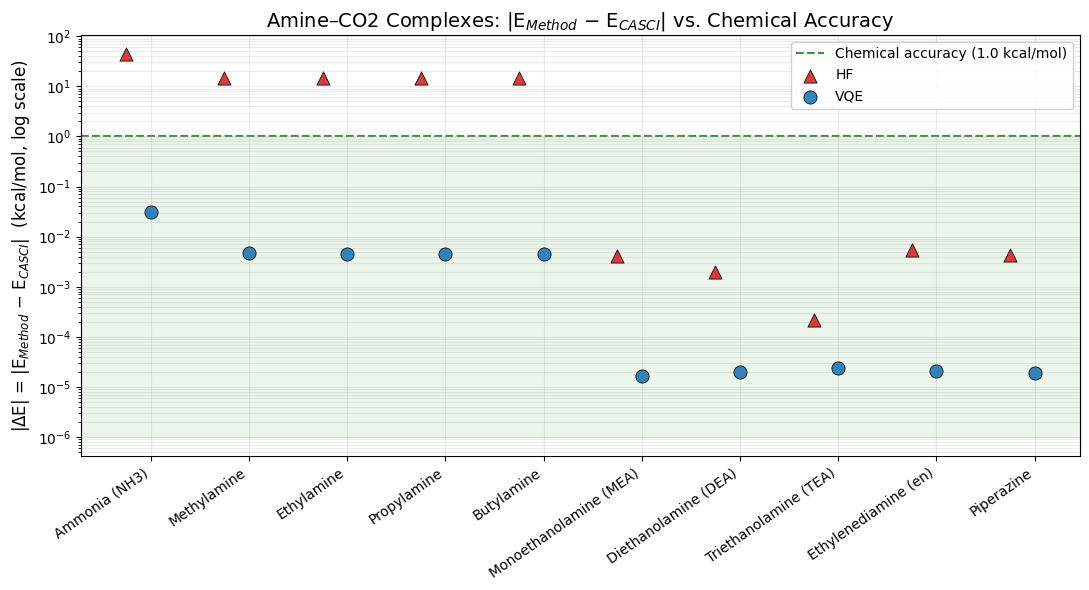

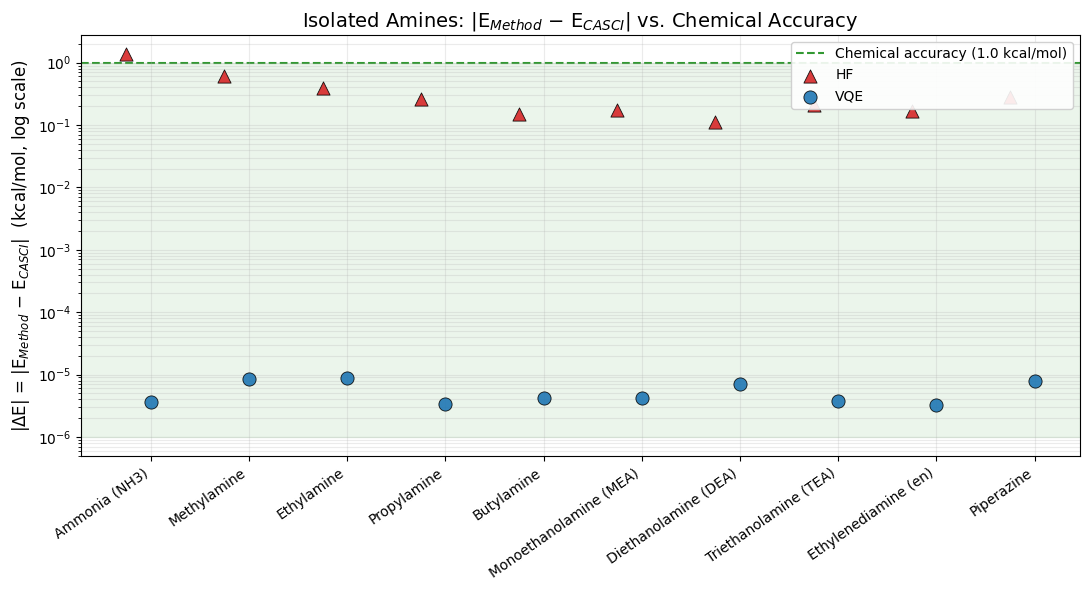

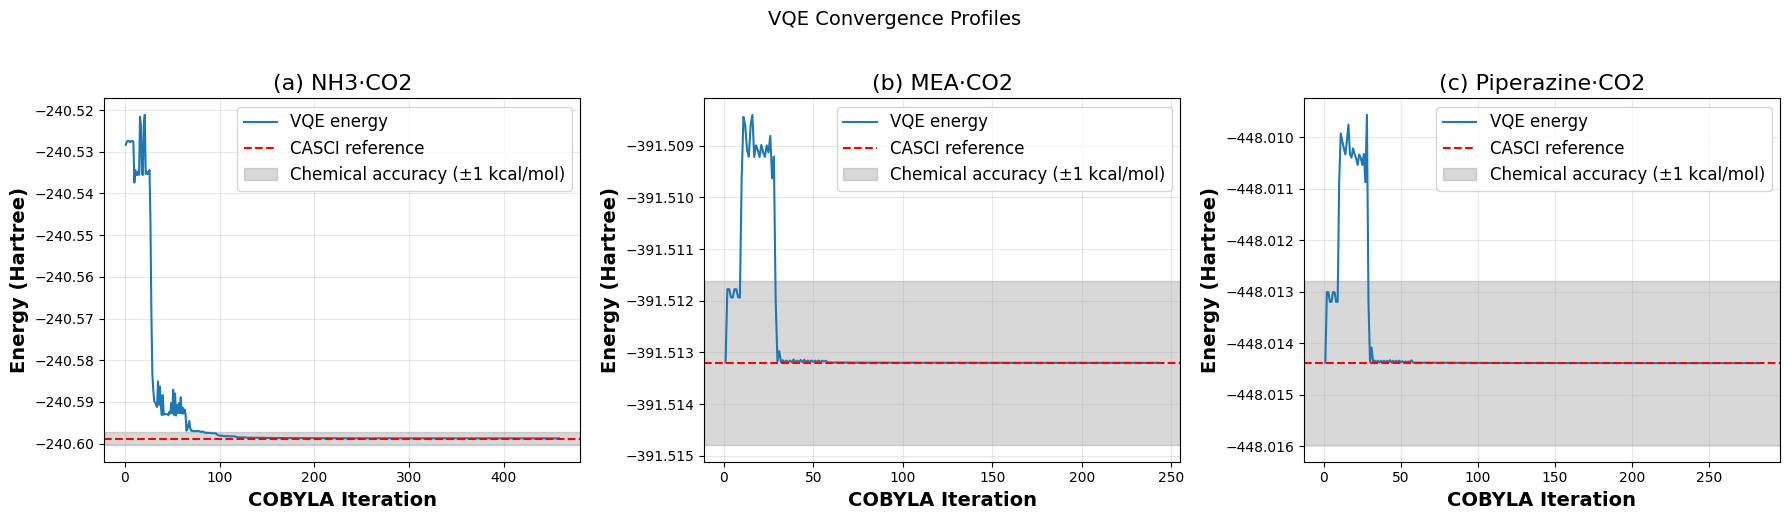

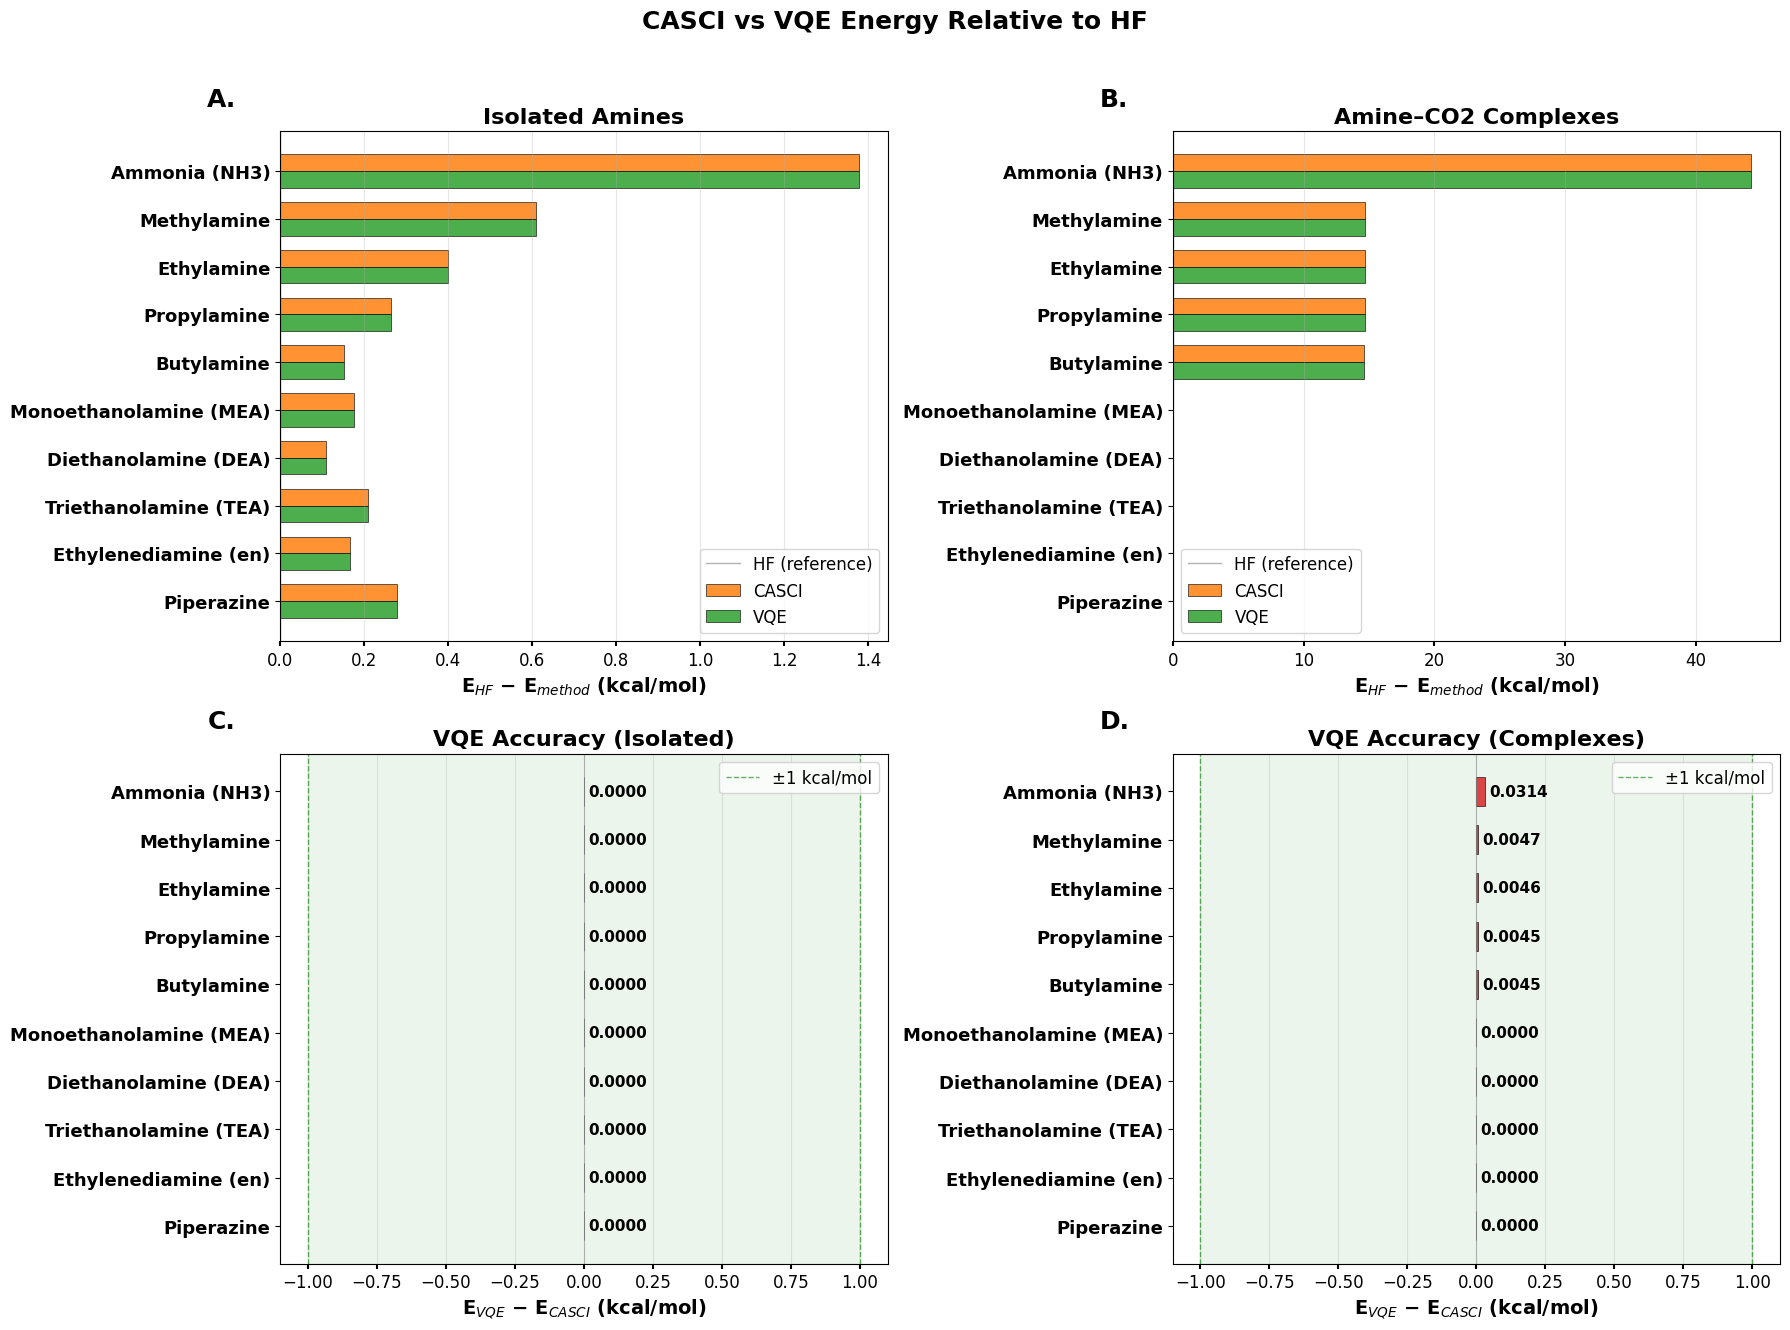


                         QUANTUM RESOURCE SCALING                       
  Category                         CAS    Qubits    UCCSD Params
  ----------------------------------------------------------------------
  Amines                         (2,3)         6               8
  Amine–CO2 complex              (4,4)         8              26
  Projected                      (6,5)        10              54


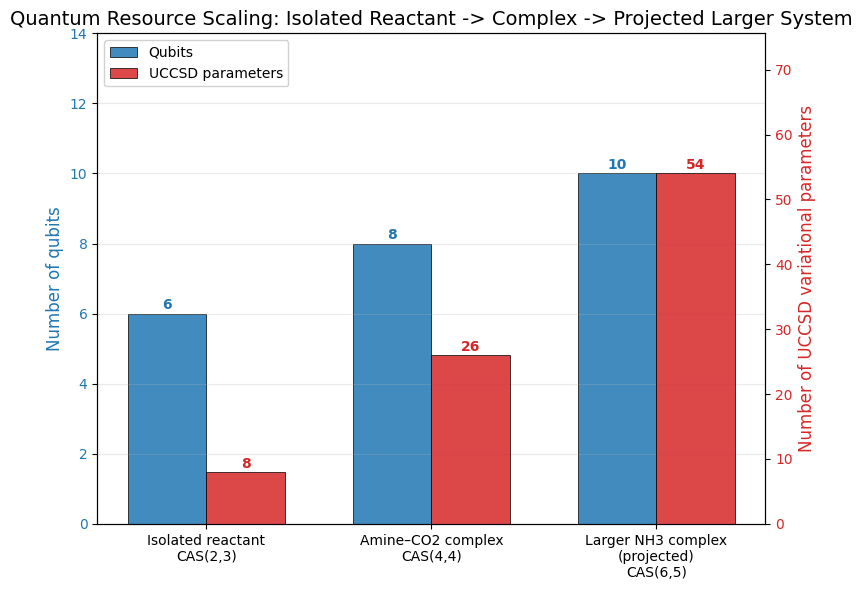

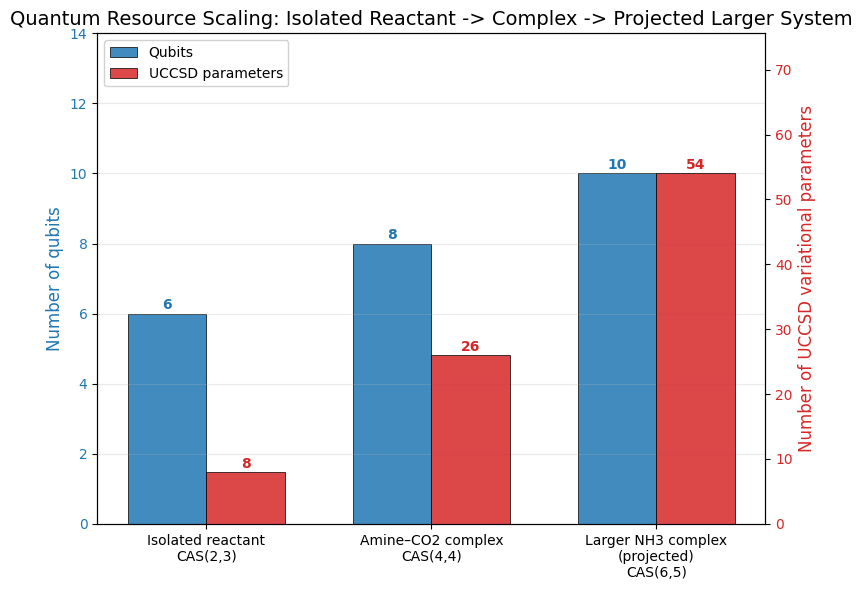

In [ ]:
import main as main_module

from utils import (
    plot_log_energy_error, plot_convergence_panel, plot_multimethod_comparison,
)
from resource_scaling import build_scaling_dataset, plot_resource_scaling, print_resource_table

AMINE_KEYS = [a["key"] for a in main_module.AMINES]
DISPLAY_NAMES = {a["key"]: a["desc"] for a in main_module.AMINES}

# ── Figure A: logarithmic energy error vs. CASCI ──
complex_order = [DISPLAY_NAMES[k] for k in AMINE_KEYS]
complex_data = {
    DISPLAY_NAMES[k]: {m: all_species_results[f"{k}_CO2_complex"][m]
                       for m in ("hf", "casci", "vqe")}
    for k in AMINE_KEYS
}
plot_log_energy_error(
    complex_data, species_order=complex_order,
    title="Amine\u2013CO2 Complexes: |E$_{Method}$ \u2212 E$_{CASCI}$| vs. Chemical Accuracy",
    filename="figureA_log_energy_error_complexes.png",
)

iso_data = {
    DISPLAY_NAMES[k]: {m: all_species_results[k][m]
                       for m in ("hf", "casci", "vqe")}
    for k in AMINE_KEYS
}
plot_log_energy_error(
    iso_data, species_order=complex_order,
    title="Amines: |E$_{Method}$ \u2212 E$_{CASCI}$| vs. Chemical Accuracy",
    filename="figureA_log_energy_error_amines.png",
)

# ── Figure 3: VQE convergence profiles (NH3, MEA, Piperazine complexes) ──
FIGURE3_SPECIES = [("NH3", "NH3\u00b7CO2"), ("MEA", "MEA\u00b7CO2"), ("Piperazine", "Piperazine\u00b7CO2")]
panel_species = []
for key, label in FIGURE3_SPECIES:
    r = all_species_results[f"{key}_CO2_complex"]
    if r["convergence"] and r["convergence"]["counts"] and r["casci"] is not None:
        panel_species.append((label, r["convergence"], r["casci"], r["problem"]))
    else:
        print(f"Skipping Figure 3 panel for {label}: missing convergence/CASCI data")

if panel_species:
    plot_convergence_panel(
        panel_species,
        filename="figure3_vqe_convergence_profiles.png",
        title="VQE Convergence Profiles",
    )

# ── Figure 4: multi-method energy comparison relative to HF ──
iso_data_full = {k: {m: all_species_results[k][m]
                     for m in ("hf", "casci", "vqe")}
                  for k in AMINE_KEYS}
cplx_data_full = {k: {m: all_species_results[f"{k}_CO2_complex"][m]
                      for m in ("hf", "casci", "vqe")}
                   for k in AMINE_KEYS}
plot_multimethod_comparison(
    iso_data_full, cplx_data_full, AMINE_KEYS, DISPLAY_NAMES,
    filename="figure4_multimethod_comparison.png",
)

# ── Figure C: quantum resource scaling ──
resource_rows = build_scaling_dataset(extra_cas=[
    (5, (3, 3), "Larger NH3 complex\n(projected)"),
])
print_resource_table(resource_rows)
plot_resource_scaling(
    resource_rows,
    title="Quantum Resource Scaling: Amines -> Amine–CO2 Complex -> Projected Larger System",
    filename="figureC_resource_scaling.png",
)
